# AI for Trustworthy Decision Making — Stage 1
# Notebook A: Data and centralised baseline
## Federated Human Activity Recognition on WISDM Actitracker

**What the project is about.** A phone's accelerometer is enough to recognise what its owner is doing (walking, sitting, ...), but this sensor data is personal. In **federated learning (FL)** each client trains on its own data and only sends model weights to a server, which averages them (**FedAvg**); the raw data never leaves the client. We compare FL against normal **centralised** training (all data in one place) on the **WISDM Actitracker** dataset: 225 people, phone accelerometer at 20 Hz, 6 activities (Walking, Jogging, Stairs, Sitting, Standing, LyingDown).

**We reuse the course repository [AITDM_FLOWER_PROJECT_TUTORIAL](https://github.com/Chiru-CatalinMihail/AITDM_FLOWER_PROJECT_TUTORIAL) wherever possible:** `split_data.py` (clients + features), `centralised.py`, `run_seeds.py` + `fl_app/` (Flower, FedAvg), `summarize.py`, `error_analysis.py`. Our own code only reads the WISDM file, cuts it into windows and makes the tables/plots.

**Team:** Yannick Koning, Mihai-Dragos Toma

| Notebook | Owner | Content |
|---|---|---|
| **A – Data & centralised** | Mihai-Dragos Toma | dataset, preprocessing, 4 data variants, client splits, centralised MLP + Random Forest |
| **B – Federated** | Yannick Koning | FedAvg on the same splits, IID reference, FedProx / balanced loss, comparison with A, literature comparison |
| **C – Better features** (extra) | Mihai-Dragos Toma | 71 hand-crafted features on the same splits, centralised + FedAvg |

**How the two parts check each other:** B and C use A's client splits and the same 56 test users unchanged, and every federated run in B has a centralised counterpart in A trained on exactly the same data, so the results can be compared one to one.

**Research questions**
* **RQ1.** How close does FedAvg (5 clients) get to centralised training on the same data?
* **RQ2.** Does more training data or more features help, centralised and federated?
* **RQ3.** How well do the models work for **new users**, and for every client equally?

### Related work
1. **Kwapisz, Weiss & Moore (2011).** *Activity Recognition using Cell Phone Accelerometers.* SIGKDD Explorations 12(2). Introduced the WISDM data (lab version, 36 people), 10-second windows and statistical features; their best model, an MLP, reached 91.7 % accuracy. We use the same window length and the same kind of features.
2. **Weiss & Lockhart (2012).** *The Impact of Personalization on Smartphone-Based Activity Recognition.* AAAI Workshop on Activity Context Representation. Models trained on *other* people are much less accurate than personal models → we test on unseen users.
3. **Alsheikh et al. (2016).** *Deep Activity Recognition Models with Triaxial Accelerometers.* AAAI Workshops (arXiv:1511.04664). A deep model on WISDM Actitracker (our dataset) with 98.2 % accuracy.
4. **Peppas et al. (2020).** *Real-Time Physical Activity Recognition on Smart Mobile Devices Using Convolutional Neural Networks.* Applied Sciences 10(23), 8482. A CNN combined with statistical features: 94.2 % on WISDM (lab, user-independent 10-fold cross-validation) but 79.1 % on Actitracker.
5. **McMahan et al. (2017).** *Communication-Efficient Learning of Deep Networks from Decentralized Data.* AISTATS. Introduced FedAvg, the aggregation method we use.

Tool: **Beutel et al. (2020).** *Flower: A Friendly Federated Learning Research Framework.* arXiv:2007.14390.

## Setup

In [ ]:
import os, sys, json, subprocess
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT = Path("/content/drive/MyDrive/AITDM_WISDM_stage1")   # shared by notebooks A and B
    REPO = Path("/content/AITDM_FLOWER_PROJECT_TUTORIAL")
    WORK = Path("/content/work")                                  # big temporary files (not in Drive)
else:  # local Jupyter
    PROJECT = Path(os.environ.get("AITDM_PROJECT", "AITDM_WISDM_stage1")).resolve()
    REPO = Path(os.environ.get("AITDM_REPO", PROJECT.parent / "AITDM_FLOWER_PROJECT_TUTORIAL")).resolve()
    WORK = PROJECT.parent / "work"
WORK.mkdir(parents=True, exist_ok=True)

# 1) the course repository
if not REPO.exists():
    subprocess.run(["git", "clone", "--depth", "1",
                    "https://github.com/Chiru-CatalinMihail/AITDM_FLOWER_PROJECT_TUTORIAL.git", str(REPO)], check=True)

# 2) its data/ and outputs/ folders live in Drive
for name in ["data", "outputs"]:
    (PROJECT / name).mkdir(parents=True, exist_ok=True)
    link = REPO / name
    if link.is_symlink() and os.path.realpath(link) != str((PROJECT / name).resolve()):
        link.unlink()                       # left over from another Drive folder: re-point it
    if not link.exists():
        link.symlink_to(PROJECT / name, target_is_directory=True)

# 3) install the packages (once)
try:
    import flwr, aitdm_fl
except ImportError:
    reqs = [l for l in (REPO / "requirements.txt").read_text().splitlines()
            if not l.startswith(("torch==", "torchvision=="))]
    (REPO / "requirements-colab.txt").write_text("\n".join(reqs))
    !pip install -q -r {REPO}/requirements-colab.txt
    !pip install -q -e {REPO}/fl_app

os.environ.setdefault("VIRTUAL_ENV", sys.prefix)  # the repo scripts expect an active environment
os.environ["CLIENT_CPUS"] = "1"                     # Flower: 2 clients train in parallel on Colab's 2 CPUs
os.chdir(REPO)
sys.path.insert(0, str(REPO / "experiments"))

PART = PROJECT / "data" / "partitions"
EXP = PROJECT / "outputs" / "experiments"
FIG = PROJECT / "figures"; FIG.mkdir(exist_ok=True)

# the 4 data variants (made in notebook A); every one uses the same 56 test users
VARIANTS = {
    "basic":        "12 features: mean/std/min/max of x, y, z",
    "rich":         "32 features: + magnitude and changes between readings",
    "overlap":      "12 features, 2x training windows (50 % overlap)",
    "rich_overlap": "32 features, 2x training windows",
}
import flwr, torch
print("flwr", flwr.__version__, "| torch", torch.__version__, "| results in", PROJECT)

Mounted at /content/drive
flwr 1.41.0 | torch 2.14.1+cpu | results in /content/drive/MyDrive/AITDM_WISDM_stage1


## 1. Dataset: WISDM Actitracker v2.0

Recorded in real life with the Actitracker phone app (WISDM Lab, Fordham University, 2013): people carried their phone in the pocket and labelled their activity.

| | |
|---|---|
| Sensor | phone accelerometer, 3 axes (x, y, z) in m/s² |
| Sampling rate | 20 Hz (one reading every 50 ms) |
| People | 225 |
| Readings | ≈ 2.98 million |
| Classes | Walking, Jogging, Stairs, Sitting, Standing, LyingDown |
| One line of the file | `user,activity,timestamp,x,y,z;` |

Downloaded from the WISDM website (or a GitHub copy of the same file).

In [ ]:
RAW = PROJECT / "data" / "raw" / "wisdm"
RAW.mkdir(parents=True, exist_ok=True)
RAW_FILE = RAW / "WISDM_at_v2.0_raw.txt"
if not RAW_FILE.exists():
    import tarfile, shutil, urllib.request
    try:   # official WISDM website
        urllib.request.urlretrieve("https://www.cis.fordham.edu/wisdm/includes/datasets/latest/WISDM_at_latest.tar.gz", RAW / "at.tar.gz")
        with tarfile.open(RAW / "at.tar.gz") as tar:
            member = next(m for m in tar.getmembers() if m.name.endswith("WISDM_at_v2.0_raw.txt"))
            with tar.extractfile(member) as src, open(RAW_FILE, "wb") as dst:
                shutil.copyfileobj(src, dst)
    except Exception:   # GitHub copy of the same file
        urllib.request.urlretrieve("https://media.githubusercontent.com/media/gomahajan/har-actitracker/master/WISDM_at_v2.0_raw.txt", RAW_FILE)
!head -3 {RAW_FILE}

1679,Walking,1370520469556,0.2941316,-0.6356053,-0.22693644;
1679,Walking,1370520469606,-0.49968776,-0.6044512,-0.22602014;
1679,Walking,1370520469656,-2.1783454,0.7134906,0.37201694;


## 2. Preprocessing

1. **Clean:** drop broken lines (e.g. `579,,;`) and corrupted readings with impossible values (> 80 m/s²).
2. **Windows of 200 readings = 10 seconds.** A window never mixes two users or two activities and never spans a gap in the recording (> 1 s between readings).
3. **Extra columns per reading** (for the "rich" variant): the magnitude `Mag` = √(x² + y² + z²), which does not depend on how the phone is held, and the change from the previous reading (`dX, dY, dZ, dMag`), which measures how "shaky" the movement is.
4. **Test users:** random people (fixed seed) until they hold ~20 % of the windows; very large users (> 2 % of all data) are skipped so no single person dominates the test set. They are never seen by any client: the test set measures how the model works for **new people**.
5. **Extra training windows (for the "overlap" variants):** a second set of windows shifted by 5 seconds (50 % overlap), **only for training users**. This doubles the training data, while the test set stays exactly the same.

In [ ]:
import pandas as pd, numpy as np

CSV, CSV_OVERLAP = WORK / "readings.csv", WORK / "readings_overlap.csv"
TEST_FILE = PROJECT / "data" / "test_users.txt"

if not (CSV.exists() and CSV_OVERLAP.exists() and TEST_FILE.exists()):
    df = pd.read_csv(RAW_FILE, header=None, names=["User", "Activity", "ts", "X", "Y", "Z"],
                     on_bad_lines="skip", dtype=str)
    df["Z"] = df["Z"].str.rstrip(";")                        # every line ends with ';'
    for c in ["User", "ts", "X", "Y", "Z"]:
        df[c] = pd.to_numeric(df[c], errors="coerce")
    df = df.dropna()                                          # broken lines
    df = df[(df[["X", "Y", "Z"]].abs() <= 80).all(axis=1)].reset_index(drop=True)   # corrupted readings
    df["User"] = df["User"].astype(int)

    # a new recording starts when the user or activity changes, or after a time gap > 1 s
    new = (df.User != df.User.shift()) | (df.Activity != df.Activity.shift()) | ~df.ts.diff().between(1, 1000)
    rec = new.cumsum()                    # recording id
    pos = df.groupby(rec).cumcount()      # position of the reading inside its recording

    # extra columns: magnitude and change from the previous reading
    df["Mag"] = np.sqrt(df.X**2 + df.Y**2 + df.Z**2)
    for c in ["X", "Y", "Z", "Mag"]:
        df["d" + c] = df.groupby(rec)[c].diff().fillna(0)
    cols = ["Window", "User", "Activity", "X", "Y", "Z", "Mag", "dX", "dY", "dZ", "dMag"]

    # windows of 200 readings (10 s), keep only full windows
    df["Window"] = rec.astype(str) + "_" + (pos // 200).astype(str)
    base = df[df.groupby("Window").Window.transform("size") == 200]

    # test users: ~20 % of the windows, no user with > 2 % of all data
    size = base.groupby("Window").User.first().value_counts().sort_index()   # windows per user
    test_users = []
    for u in np.random.default_rng(42).permutation(size.index):
        if size[u] <= 0.02 * size.sum():
            test_users.append(int(u))
        if size[test_users].sum() >= 0.2 * size.sum():
            break
    TEST_FILE.write_text(",".join(map(str, sorted(test_users))))

    # extra windows shifted by 100 readings (5 s), training users only
    shifted = df[(pos >= 100) & ~df.User.isin(test_users)].copy()
    shifted["Window"] = rec.astype(str) + "_s" + ((pos - 100) // 200).astype(str)
    shifted = shifted[shifted.groupby("Window").Window.transform("size") == 200]

    base[cols].to_csv(CSV, index=False)
    pd.concat([base[cols], shifted[cols]]).to_csv(CSV_OVERLAP, index=False)
    print(f"{len(df):,} clean readings -> {base.Window.nunique():,} windows "
          f"(+ {shifted.Window.nunique():,} shifted training windows)")

TEST_USERS = TEST_FILE.read_text().strip()
print("test users:", len(TEST_USERS.split(",")))

2,980,760 clean readings -> 13,381 windows (+ 10,450 shifted training windows)
test users: 56


### A first look at the data

13,381 windows from 223 users, 2680 test windows (20%) from 56 users

col_0      test users  training users  share
Activity                                    
Jogging           583            1100  0.126
LyingDown         130            1215  0.101
Sitting           410            2452  0.214
Stairs             81             199  0.021
Standing          187            1110  0.097
Walking          1289            4625  0.442


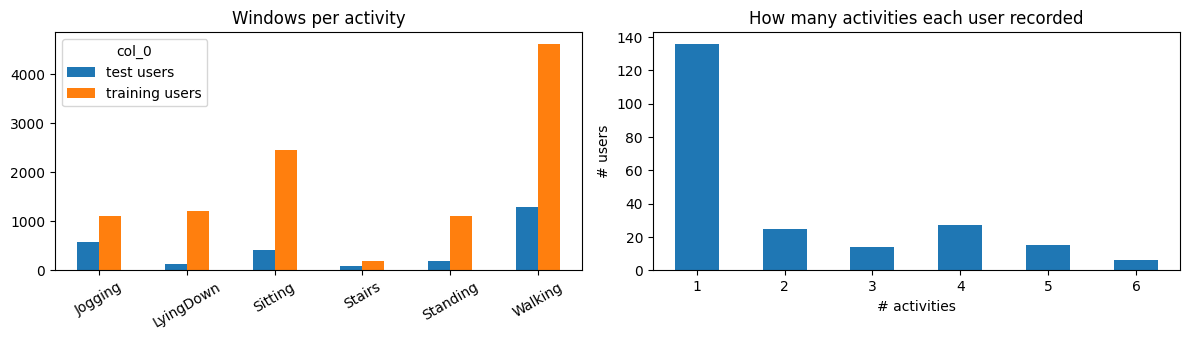

In [ ]:
import matplotlib.pyplot as plt
windows = pd.read_csv(CSV, usecols=["Window", "User", "Activity"]).groupby("Window").first()
test_set = windows.User.isin([int(u) for u in TEST_USERS.split(",")])
counts = pd.crosstab(windows.Activity, np.where(test_set, "test users", "training users"))
print(f"{len(windows):,} windows from {windows.User.nunique()} users, "
      f"{test_set.sum()} test windows ({test_set.mean():.0%}) from {len(TEST_USERS.split(','))} users\n")
print(counts.assign(share=(counts.sum(axis=1) / counts.values.sum()).round(3)))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
counts.plot.bar(ax=axes[0], rot=30); axes[0].set(title="Windows per activity", xlabel="")
windows.groupby("User").Activity.nunique().value_counts().sort_index().plot.bar(ax=axes[1], rot=0)
axes[1].set(title="How many activities each user recorded", xlabel="# activities", ylabel="# users")
fig.tight_layout(); fig.savefig(FIG / "data_overview.png", dpi=150); plt.show()

**What the data looks like**
* **223 of the 225 people** have at least one complete 10-second window; the other 2 drop out.
* **Very imbalanced classes:** Walking is ~44 % of the windows, Stairs only ~2 %. Accuracy alone would hide mistakes on rare classes, so we also report **balanced accuracy** (the average recall over the 6 classes) and **macro-F1**.
* **Every person is different:** some people recorded hundreds of windows, most only a few, and most recorded just one or two activities. Splitting the data **by person** therefore gives clients with very different data (non-IID), as in real FL.
* **LyingDown is suspicious:** more than half of the LyingDown windows come from a single person, whose phone records almost no gravity (≈ 0 m/s² instead of ≈ 9.8 m/s²). A model can learn this quirk instead of the activity. We keep the data as it is, but it explains some results later (and is a topic for Stage 2).

## 3. Federated setup: how the data is split into clients

We simulate **5 clients**. The repository's `split_data.py` makes the clients and the features:

* `--strategy group --group-col User`: every **person belongs to exactly one client**, so each client is a small group of real people with its own mix of activities (**non-IID**, as in real FL). Each client keeps 15 % of its windows for validation.
* `--test-groups`: the 56 test users go to the server's test set only.
* `--sample-col Window`: a window has 200 rows (readings), so `split_data.py` summarises every chosen column with **mean, std, min and max** → `basic`: 3 columns × 4 = 12 features; `rich`: 8 columns × 4 = 32 features.
* An extra **IID** split of the basic data (windows dealt at random, every client gets the same mix) is the unrealistic reference for notebook B.

| Variant | Data | Features | Training windows |
|---|---|---|---|
| `basic` | `readings.csv` | x, y, z → 12 | ≈ 10.7 k |
| `rich` | `readings.csv` | x, y, z, Mag, dX, dY, dZ, dMag → 32 | ≈ 10.7 k |
| `overlap` | `readings_overlap.csv` | 12 | ≈ 21 k |
| `rich_overlap` | `readings_overlap.csv` | 32 | ≈ 21 k |

In [ ]:
FEATS = {"basic": "^[XYZ]$", "rich": "^d?(X|Y|Z|Mag)$"}
jobs = {  # partition name: (csv, feature columns, strategy)
    "user5_basic":        (CSV,         FEATS["basic"], "group"),
    "user5_rich":         (CSV,         FEATS["rich"],  "group"),
    "user5_overlap":      (CSV_OVERLAP, FEATS["basic"], "group"),
    "user5_rich_overlap": (CSV_OVERLAP, FEATS["rich"],  "group"),
    "iid5_basic":         (CSV,         FEATS["basic"], "iid"),
}
for name, (csv, feats, strategy) in jobs.items():
    if not (PART / name / "meta.json").exists():
        print(f"--- {name}")
        !python data_splitting/split_data.py --input {csv} --label-col Activity --sample-col Window \
            --feature-cols "{feats}" --strategy {strategy} --group-col User --num-clients 5 \
            --test-groups {TEST_USERS} --seed 42 --out {PART / name} > {WORK}/split_{name}.log

summary = []
for name in jobs:
    meta = json.loads((PART / name / "meta.json").read_text())
    summary.append({"partition": name, "features": len(meta["feature_names"]),
                    "train windows": sum(c["train"] for c in meta["clients"]),
                    "val windows": sum(c["val"] for c in meta["clients"]),
                    "test windows": meta["test_samples"]})
pd.DataFrame(summary)

--- user5_basic
--- user5_rich
--- user5_overlap
--- user5_rich_overlap
--- iid5_basic


,partition,features,train windows,val windows,test windows
0,user5_basic,12,9096,1605,2680
1,user5_rich,32,9096,1605,2680
2,user5_overlap,12,17980,3171,2680
3,user5_rich_overlap,32,17980,3171,2680
4,iid5_basic,12,9096,1605,2680


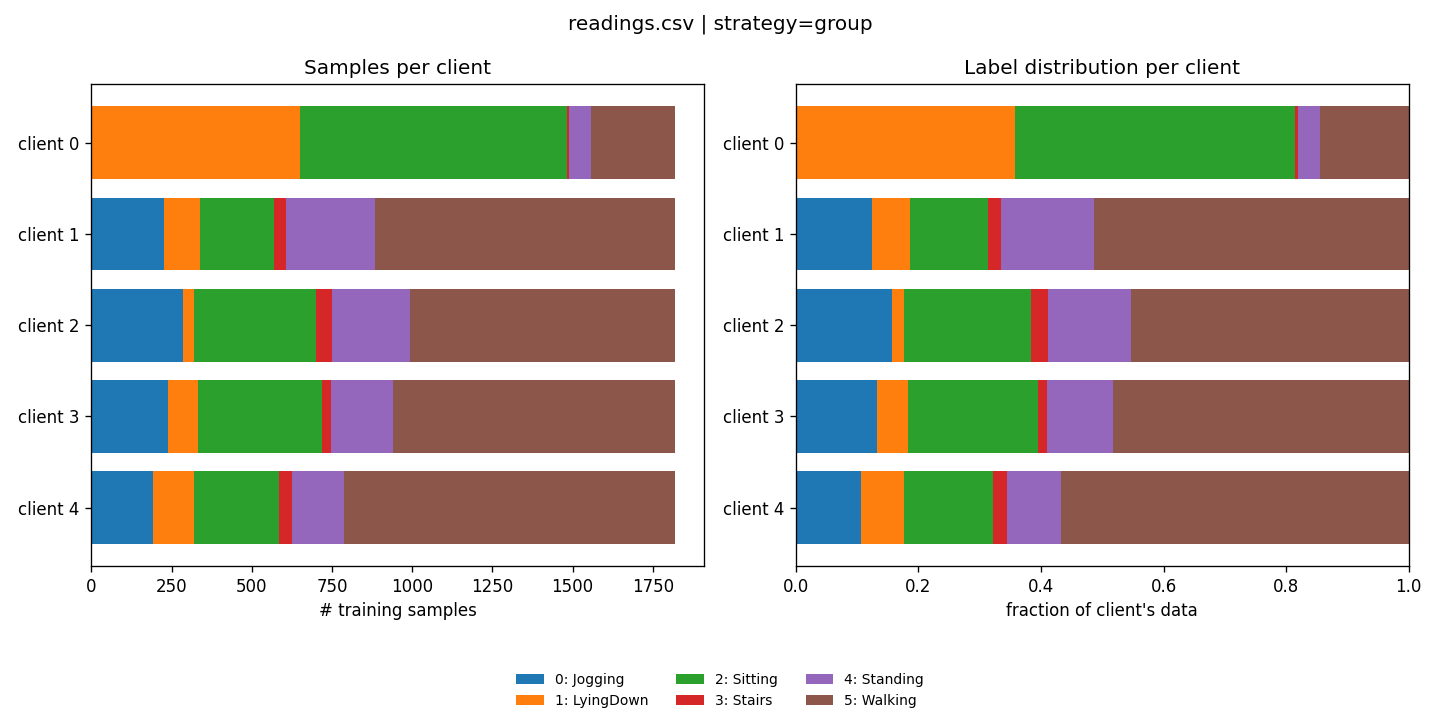

In [ ]:
from IPython.display import Image, display
display(Image(str(PART / "user5_basic" / "label_distribution.png"), width=900))

The clients have similar sizes but different activity mixes (non-IID). One client is dominated by Sitting/LyingDown, the others by Walking.

## 4. Centralised baseline: MLP

**Model:** the repository's MLP (`build_mlp()` in `fl_app/aitdm_fl/task.py`), the same network notebook B uses for FL: `features → 256 → 128 → 6` (ReLU, dropout), Adam, learning rate 0.001, batch size 32.

**Centralised** = the training data of all 5 clients put together, as if privacy did not matter (`experiments/centralised.py`). 30 epochs = the same amount of training as 10 FL rounds × 3 local epochs in notebook B. Seeds 1, 2, 3, reported as mean ± std. All variants are tested on the **same 2,680 test windows** (56 new users).

In [ ]:
for v in VARIANTS:
    if not (EXP / f"central-{v}" / "summary.json").exists():
        print(f"===== central-{v} =====", flush=True)
        !python experiments/centralised.py --partitions {PART}/user5_{v} --epochs 30 --seeds 1 2 3 --name central-{v} > {WORK}/central_{v}.log 2>&1
        !tail -4 {WORK}/central_{v}.log

===== central-basic =====
central-basic (3 seeds, mean +- std)
  val   acc. 0.901 ± 0.003, bal. acc. 0.841 ± 0.012, macro-F1 0.860 ± 0.006
  test  acc. 0.796 ± 0.001, bal. acc. 0.641 ± 0.004, macro-F1 0.621 ± 0.002
  val per client: 0: 0.908 ± 0.002, 1: 0.904 ± 0.004, 2: 0.865 ± 0.017, 3: 0.912 ± 0.004, 4: 0.917 ± 0.012
===== central-rich =====
central-rich (3 seeds, mean +- std)
  val   acc. 0.913 ± 0.005, bal. acc. 0.879 ± 0.016, macro-F1 0.883 ± 0.008
  test  acc. 0.798 ± 0.009, bal. acc. 0.669 ± 0.014, macro-F1 0.654 ± 0.013
  val per client: 0: 0.921 ± 0.008, 1: 0.914 ± 0.010, 2: 0.893 ± 0.005, 3: 0.923 ± 0.005, 4: 0.916 ± 0.005
===== central-overlap =====
central-overlap (3 seeds, mean +- std)
  val   acc. 0.934 ± 0.003, bal. acc. 0.905 ± 0.008, macro-F1 0.905 ± 0.006
  test  acc. 0.787 ± 0.015, bal. acc. 0.639 ± 0.014, macro-F1 0.623 ± 0.015
  val per client: 0: 0.922 ± 0.002, 1: 0.952 ± 0.012, 2: 0.909 ± 0.007, 3: 0.932 ± 0.004, 4: 0.957 ± 0.002
===== central-rich_overlap =====

## 5. Centralised reference: Random Forest

A classic, strong model for this kind of statistical features (in the spirit of Kwapisz et al., 2011), trained on exactly the same data. It is a **centralised-only** reference: FedAvg averages neural-network weights, and a forest of decision trees cannot be averaged like that.

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score

RF_FILE = PROJECT / "results" / "random_forest.csv"
RF_FILE.parent.mkdir(exist_ok=True)
if not RF_FILE.exists():
    rows = []
    for v in VARIANTS:
        clients = [np.load(f) for f in sorted((PART / f"user5_{v}").glob("client_*.npz"))]
        X_train = np.concatenate([c["x_train"] for c in clients]); y_train = np.concatenate([c["y_train"] for c in clients])
        X_val = np.concatenate([c["x_val"] for c in clients]);     y_val = np.concatenate([c["y_val"] for c in clients])
        test = np.load(PART / f"user5_{v}" / "test.npz")
        for seed in [1, 2, 3]:
            rf = RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=seed).fit(X_train, y_train)
            pv, pt = rf.predict(X_val), rf.predict(test["x_test"])
            rows.append({"variant": v, "seed": seed,
                         "val_accuracy": accuracy_score(y_val, pv), "val_balanced_accuracy": balanced_accuracy_score(y_val, pv),
                         "test_accuracy": accuracy_score(test["y_test"], pt),
                         "test_balanced_accuracy": balanced_accuracy_score(test["y_test"], pt),
                         "test_f1_macro": f1_score(test["y_test"], pt, average="macro")})
        print("done:", v)
    pd.DataFrame(rows).to_csv(RF_FILE, index=False)
rf = pd.read_csv(RF_FILE)

done: basic
done: rich
done: overlap
done: rich_overlap


## 6. Results (centralised)

*Val* = the clients' validation windows (people seen in training; optimistic, and for the overlap variants even more so, because overlapping windows share readings). *Test* = the 56 held-out users: **the number that matters**.

In [ ]:
from summarize import summarize_experiment

def ms(mean, std):
    return f"{mean:.3f} ± {std:.3f}"

rows = []
for v, desc in VARIANTS.items():
    s = summarize_experiment(EXP / f"central-{v}", quiet=True)
    st = lambda k, m: ms(s[k][m]["mean"], s[k][m]["std"])
    rows.append({"Model": "MLP", "Data variant": v,
                 "Val acc.": st("val", "accuracy"), "Test acc.": st("test", "accuracy"),
                 "Test bal. acc.": st("test", "balanced_accuracy"), "Test macro-F1": st("test", "f1_macro")})
for v in VARIANTS:
    r = rf[rf.variant == v]
    rows.append({"Model": "Random Forest", "Data variant": v,
                 "Val acc.": ms(r.val_accuracy.mean(), r.val_accuracy.std()),
                 "Test acc.": ms(r.test_accuracy.mean(), r.test_accuracy.std()),
                 "Test bal. acc.": ms(r.test_balanced_accuracy.mean(), r.test_balanced_accuracy.std()),
                 "Test macro-F1": ms(r.test_f1_macro.mean(), r.test_f1_macro.std())})
central_table = pd.DataFrame(rows)
central_table.to_csv(PROJECT / "results" / "centralised.csv", index=False)
central_table

,Model,Data variant,Val acc.,Test acc.,Test bal. acc.,Test macro-F1
0,MLP,basic,0.901 ± 0.003,0.796 ± 0.001,0.641 ± 0.004,0.621 ± 0.002
1,MLP,rich,0.913 ± 0.005,0.798 ± 0.009,0.669 ± 0.014,0.654 ± 0.013
2,MLP,overlap,0.934 ± 0.003,0.787 ± 0.015,0.639 ± 0.014,0.623 ± 0.015
3,MLP,rich_overlap,0.944 ± 0.003,0.801 ± 0.008,0.678 ± 0.007,0.666 ± 0.005
4,Random Forest,basic,0.953 ± 0.001,0.806 ± 0.006,0.679 ± 0.008,0.670 ± 0.010
5,Random Forest,rich,0.950 ± 0.000,0.805 ± 0.007,0.658 ± 0.018,0.650 ± 0.021
6,Random Forest,overlap,0.976 ± 0.000,0.789 ± 0.002,0.670 ± 0.003,0.648 ± 0.003
7,Random Forest,rich_overlap,0.976 ± 0.000,0.810 ± 0.001,0.694 ± 0.005,0.681 ± 0.004


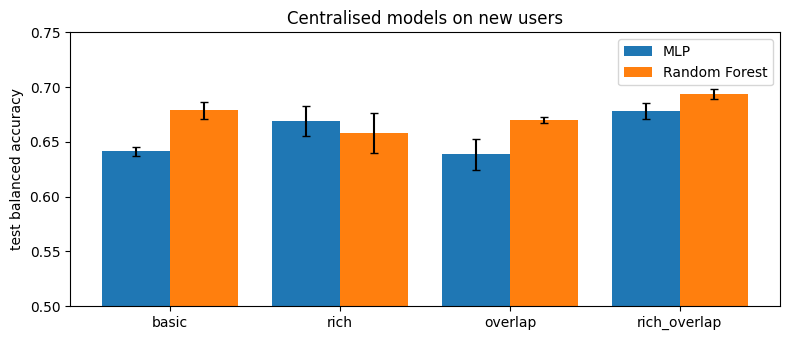

In [ ]:
# test balanced accuracy per variant, MLP vs Random Forest
fig, ax = plt.subplots(figsize=(8, 3.5))
x = np.arange(len(VARIANTS))
mlp = [summarize_experiment(EXP / f"central-{v}", quiet=True)["test"]["balanced_accuracy"] for v in VARIANTS]
ax.bar(x - 0.2, [m["mean"] for m in mlp], 0.4, yerr=[m["std"] for m in mlp], capsize=3, label="MLP")
ax.bar(x + 0.2, [rf[rf.variant == v].test_balanced_accuracy.mean() for v in VARIANTS], 0.4,
       yerr=[rf[rf.variant == v].test_balanced_accuracy.std() for v in VARIANTS], capsize=3, label="Random Forest")
ax.set_xticks(x, list(VARIANTS)); ax.set_ylim(0.5, 0.75); ax.set_ylabel("test balanced accuracy")
ax.set_title("Centralised models on new users"); ax.legend()
fig.tight_layout(); fig.savefig(FIG / "centralised_variants.png", dpi=150); plt.show()

**Where does the centralised MLP make mistakes on new users?** (repository's `error_analysis.py`, best variant, seed 1)

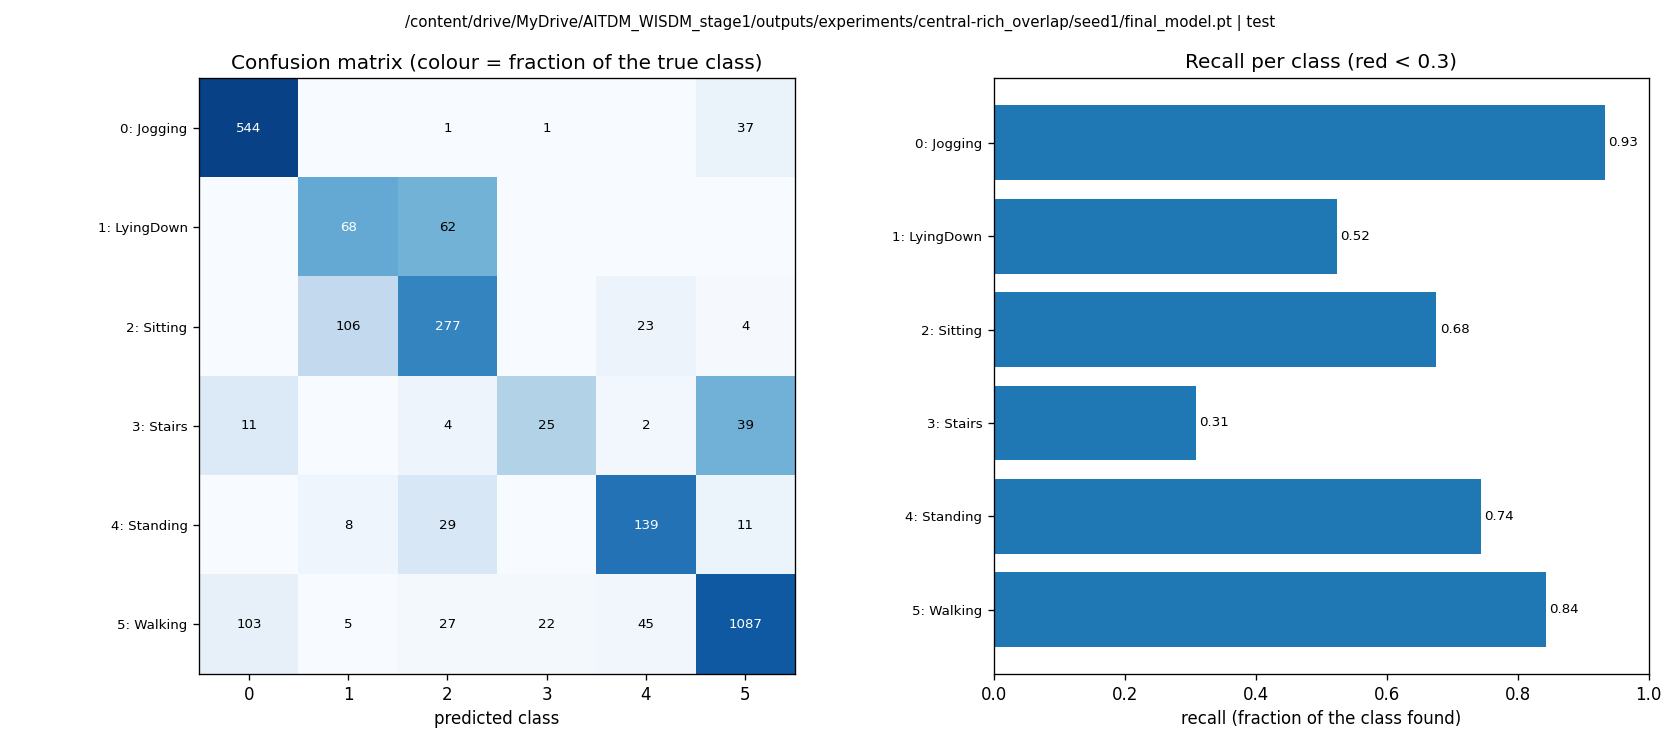

In [ ]:
run = EXP / "central-rich_overlap" / "seed1"
!python explainability/error_analysis.py --run {run} --data test > /dev/null
display(Image(str(run / "errors_test.png"), width=850))

**Next:** open notebook B, which trains the same MLP with federated learning on the same client splits and compares the results with this notebook.